In [17]:
import os

from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict, List
from pydantic import BaseModel, Field
import operator

from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from langsmith import traceable

from dotenv import load_dotenv

In [18]:
load_dotenv(".env.langsmith")

True

In [19]:
os.environ['LANGSMITH_PROJECT'] = 'Langgraph_Project_3'

In [20]:
simple_model = ChatOpenAI(
    model = 'gpt-4o-mini'
)

In [21]:
class FeedbackState(TypedDict):
    essay: str
    language_feedback: str
    aod_feedback: str
    cot_feedback: str
    overall_feedback: str
    
    scores: Annotated[List[int], operator.add]
    average_score: float

In [22]:
# Pydantic class for feedback and score

class EvaluationSchema(BaseModel):
    feedback: Annotated[str, Field(description = 'Get the feedback for the essay')]
    score: Annotated[int, Field(description = "Generate score out oof 10", gt = 0, le = 10)]

In [23]:
structured_model = simple_model.with_structured_output(
    schema = EvaluationSchema)

# Checking the model

In [24]:
essay = '''Role of India in Artificial Intelligence
Introduction

Artificial Intelligence (AI) has emerged as one of the most transformative technologies of the 21st century, reshaping industries, governance, and societies worldwide. For India—a nation with a massive population, vibrant IT sector, and rapidly expanding digital infrastructure—the rise of AI presents both opportunities and challenges. The role of India in AI is multifaceted, encompassing research, innovation, policy-making, talent development, and global collaboration. As one of the fastest-growing economies, India is poised to be a major contributor to the global AI ecosystem.

India’s Position in the Global AI Landscape

India has positioned itself as a significant player in the AI race, not by competing purely on cutting-edge innovation like the United States or China, but by focusing on AI for social good and inclusive growth. With over 750 million internet users, abundant data, and a thriving start-up ecosystem, India is leveraging AI in critical sectors such as agriculture, healthcare, education, and governance. Reports suggest that AI could contribute $1 trillion to India’s economy by 2035, highlighting its potential as a growth driver.

Government Initiatives and Policies

The Indian government has recognized AI as a strategic technology. Some notable initiatives include:

NITI Aayog’s National Strategy for Artificial Intelligence (2018) – Framed around the concept of “AI for All,” this strategy emphasizes responsible AI adoption in healthcare, agriculture, education, smart mobility, and smart cities.

National AI Portal (2020) – A platform to promote AI-related research, knowledge sharing, and collaboration.

Digital India Mission – Creating the necessary digital infrastructure for widespread AI adoption.

IndiaAI Mission (2023) – A national program to establish AI computing infrastructure, datasets, and ethical frameworks.

These initiatives reflect India’s approach of using AI not just for economic competitiveness, but also for addressing socio-economic challenges.

AI Research and Innovation in India

India has emerged as a hub of AI research and development, driven by both academia and industry:

Academic Contributions: Prestigious institutions like IITs, IISc Bangalore, and IIITs are conducting advanced research in machine learning, computer vision, and natural language processing (NLP). Indian researchers are particularly active in multilingual AI, focusing on building models for the country’s 22 scheduled languages.

Industry and Startups: India hosts more than 3,000 AI startups, many of which focus on affordable healthcare diagnostics, precision agriculture, fintech, and logistics. Unicorns like Ola, Flipkart, and Zomato are also deploying AI for customer engagement and operational efficiency.

Big Tech Presence: Companies like Google, Microsoft, Amazon, and IBM have AI research labs in India, contributing to global innovation while tapping into local talent.

Applications of AI in India

AI’s role in India extends beyond industry growth—it is transforming governance and public services:

Healthcare – AI-driven tools are improving early disease detection, telemedicine, and drug discovery. Startups are using AI for diagnosing tuberculosis, cancer, and eye disorders.

Agriculture – AI models predict crop yields, detect pest infestations, and optimize irrigation, benefiting farmers with small landholdings.

Education – AI-powered personalized learning platforms are bridging gaps in rural education.

Smart Cities & Governance – AI is used in traffic management, surveillance, and digital identity systems like Aadhaar to improve service delivery.

Financial Services – AI is enabling fraud detection, credit scoring, and digital banking for financial inclusion.

Challenges for India in AI Development

Despite its progress, India faces several challenges in becoming a global AI leader:

Data Privacy and Ethics – Balancing AI innovation with citizens’ rights remains a challenge due to the lack of comprehensive data protection laws.

Skilled Workforce Gap – While India produces millions of engineers annually, there is a shortage of highly skilled AI researchers and practitioners.

Infrastructure Limitations – AI research requires high computing power and reliable digital infrastructure, which are not yet universally available.

Unequal Access – There is a risk of AI benefits being concentrated in urban areas, leaving rural regions behind.

India’s Future Role in Global AI

Looking ahead, India’s role in AI is likely to be characterized by inclusivity, affordability, and ethical innovation. Instead of competing head-on with the U.S. and China in military or surveillance AI, India is prioritizing AI for sustainable development. Its future role could involve:

Becoming a global hub for AI talent, given its large pool of engineers and data scientists.

Leading in multilingual and culturally adaptive AI, making technology more inclusive for diverse populations.

Driving frugal innovation—building cost-effective AI solutions for healthcare, agriculture, and education that can be exported to other developing nations.

Shaping global AI ethics and governance frameworks, especially around responsible use and privacy.

Conclusion

India’s journey in Artificial Intelligence is not just about technological advancement but also about ensuring equitable growth and social impact. With its emphasis on “AI for All,” India is striving to create a unique AI ecosystem that balances innovation with inclusivity. By investing in research, nurturing talent, and adopting responsible governance, India has the potential to emerge as a global leader—not by mimicking other nations’ AI models, but by crafting one that addresses the needs of its people and sets an example for the developing world.'''

In [25]:
essay2 = '''India in Artificial Intelligent

India is now going big in artificial intelligence but still not very big like USA or China. Many company in India want to do AI but sometime no good resources and no enough expert people. Government also saying AI is future, but policy is sometime confusing and not always working good.

Lot of startup in Bangalore, Hyderabad and also Delhi doing AI thing like chatbot, health care machine, education software. But many project not complete proper and some only copy from west. Still India student is very smart and many go to America to study AI then later make big company or work in Google or Microsoft.

Indian AI also used in farming, like machine look at crop and tell farmer about soil, but sometime farmer no have internet so it not help much. In health also some hospital use AI for scan x-ray and find disease, but only big hospital in city have this, village hospital no have.

Future India want to be global hub for AI, but for that need more training, more infrastructure and less brain drain. Many people say if India combine AI with huge population and data, it can be very strong, but must also care about job lost, because robot and AI maybe take job from normal people.

So, India AI is like young baby, still learning walk, but one day maybe run fast if everything work out.'''

In [26]:
prompt = f'''Evaluate the language quality of the below given essay, give the feedback and generate a score out of 10

{essay}'''

response = structured_model.invoke(prompt)

In [27]:
response.score

7

In [28]:
# Creating nodes

@traceable(name = 'evaluate_language', tags = ['LanguageEvaluation'], metadata = {'model': "gpt-4o-mini", 'type': 'structured_model'})
def language_analysis(state: FeedbackState) -> FeedbackState:

    essay = state['essay']

    prompt = f'''You are an expert writer, journalist and editor. Evaluate the below given essay
        based on language, provide a feedback and assign a score out of 10.
        
        {essay}'''

    # invoking LLM
    response = structured_model.invoke(prompt)

    ret = {"language_feedback": response.feedback, 'scores': [response.score]}

    return ret

#--------------------------------------------------------------------------------------------------------

@traceable(name = 'analysis_of_depth', metadata = {'model': "gpt-4o-mini", 'type': 'structured_model'})
def aod_analysis(state: FeedbackState) -> FeedbackState:
    essay = state['essay']

    prompt = f'''You are an expert writer, journalist and editor.
    Analyse depth of below essay, generate feedback and give score out of 10.
    
    {essay}'''

    # invoking LLM
    response = structured_model.invoke(prompt)

    ret = {"aod_feedback": response.feedback, 'scores': [response.score]}

    return ret

#--------------------------------------------------------------------------------------------------------

@traceable(name = 'clarity_of_thoughts', metadata = {'model': "gpt-4o-mini", 'type': 'structured_model'})
def cot_analysis(state: FeedbackState) ->FeedbackState:
    
    # Fetchinh essay
    essay = state['essay']

    # Creating PromptTemplate
    template = PromptTemplate(
        template = '''You are an expert writer, journalist and editor. Evaluate the below given essay
        based on clarity of thoughts, provide a feedback and assign a score out of 10.
        
        {essay}''',
        input_variables = ["essay"] 
    )

    # Invoking template
    prompt = template.invoke({"essay": essay})

    # Invoking LLM
    response = structured_model.invoke(prompt)

    # Returning required state
    ret_state = {"cot_feedback": response.feedback, "scores": [response.score]}

    return ret_state

#--------------------------------------------------------------------------------------------------------

@traceable(name = 'summary', metadata = {'model': "gpt-4o-mini", 'type': 'structured_model'})
def summary(state: FeedbackState) ->FeedbackState:
    language_feedback = state['language_feedback']
    aod_feedback = state['aod_feedback']
    cot_feedback = state["cot_feedback"]
    scores = state['scores']

    # Creating prompt without PromptTemplate
    prompt = f'''You are an expert writer, journalist and editor. Summarize the below given feedbacks.

    Clarity of Thought feedback - {cot_feedback}
    Analysis of Depth feedback - {aod_feedback}
    Language feedback - {language_feedback}
    '''
    
    # Invoking LLM
    response = simple_model.invoke(prompt).content

    # Averaging the scores
    average_score = sum(scores)/len(scores)

    # Returning required state
    ret_state = {"overall_feedback": response, "average_score": average_score}

    return ret_state

In [29]:
# Creating the graph
graph = StateGraph(FeedbackState)

# Adding nodes
graph.add_node('language_analysis', language_analysis)
graph.add_node('aod_analysis', aod_analysis)
graph.add_node("cot_analysis", cot_analysis)
graph.add_node("summary", summary)

# Creating edges
graph.add_edge(START, "cot_analysis")
graph.add_edge(START, "aod_analysis")
graph.add_edge(START, "language_analysis")

graph.add_edge("cot_analysis", "summary")
graph.add_edge("aod_analysis", "summary")
graph.add_edge("language_analysis", "summary")

graph.add_edge("summary", END)


workflow = graph.compile()


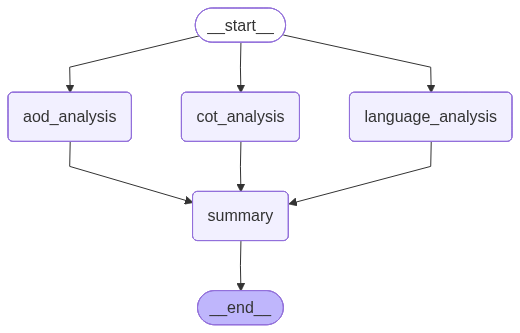

In [30]:
workflow

In [31]:
initial_state = {'essay': essay}
response = workflow.invoke(initial_state)

In [32]:
response.keys()

dict_keys(['essay', 'language_feedback', 'aod_feedback', 'cot_feedback', 'overall_feedback', 'scores', 'average_score'])

In [33]:
response['overall_feedback']

"The feedback on the essay regarding India's role in Artificial Intelligence highlights several strengths and areas for improvement across three key aspects: clarity of thought, analysis of depth, and language.\n\n**Clarity of Thought:** The essay presents a clear thesis and logically organized structure, effectively covering India's initiatives, research landscape, and applications in AI. It successfully balances advancements and challenges, though some sections could be more concise for improved readability. The conclusion reiterates main points but could benefit from a stronger closing statement to emphasize India's unique position globally.\n\n**Analysis of Depth:** The essay offers a thorough overview of various dimensions of India's AI landscape, including government initiatives and future outlook. However, it lacks in-depth analysis of specific case studies and comparative insights with other countries. While challenges are mentioned, a more detailed exploration of potential sol

In [13]:
# Invoking the workflow.

initial_state = {'essay': essay2}
config = {'run_name': 'evaluate_essay_2',
         "tags": ['evaluate_essay', "language", 'depth', 'thoughts'],
         "metadata": {'model': 'openai'}}

response = workflow.invoke(initial_state, config = config)